# The Semantic Gap and Metadata

A text retrieval system answers a query by matching words. A photo contains no words. This
notebook follows the book sections *The Semantic Gap* and *Metadata and Its Limits* on the
chapter's running example, a photo of the Taj Mahal. We look at what the computer stores, read
the metadata that the camera and the photographer wrote into the file, attach a faceted
annotation, compare two annotators, and harvest the text of a web page. At the end, we check
which user queries each metadata source can answer.

These are the queries from Figure 9.4 of the book:

- building, outdoor, sky
- mausoleum, tomb, dome, minaret
- UNESCO World Heritage Site
- Taj Mahal, Indian architecture
- where is Mumtaz Mahal buried?

**Learning goals:**
- See that an image file stores millions of numbers and no concepts
- Read EXIF and IPTC/XMP metadata from a real photo, and see what an upload removes
- Organize metadata in facets with generic, specific, and abstract values
- Compare two annotators by shared words and by embedding similarity
- Harvest the text around an image on a web page, and see why the source order misleads
- Check which queries each metadata source answers, and why a match is only a claim

**Prerequisites:** Chapter 1 (tokenization and term matching), Chapter 5 (sentence embeddings)

**Data:** `data/images/taj_mahal.jpg` is the Wikimedia Commons photo
[Taj Mahal, Agra, India3.jpg](https://commons.wikimedia.org/wiki/File:Taj_Mahal,_Agra,_India3.jpg)
by Joe deSousa (CC0), cropped to 4:3 and resized to 1024 by 768 pixels. Its metadata is kept.
The two web pages in `data/ch09/` were written for this demo.

## Setup

In [1]:
import json
import math
import os
import re
import xml.etree.ElementTree as ET
from io import BytesIO
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from PIL.ExifTags import GPSTAGS, IFD, TAGS
from bs4 import BeautifulSoup, Comment, NavigableString

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # quiet model downloads
os.environ["HF_HUB_VERBOSITY"] = "error"
from sentence_transformers import SentenceTransformer

from shared.display import print_table, display_md
from shared.text import pipeline

PHOTO = Path("data/images/taj_mahal.jpg")
QUERIES = [
    "building, outdoor, sky",
    "mausoleum, tomb, dome, minaret",
    "UNESCO World Heritage Site",
    "Taj Mahal, Indian architecture",
    "where is Mumtaz Mahal buried?",
]

## 1. What the Computer Stores

The book's example photo has 1024 by 768 pixels with three color channels. Our photo has the
same size, so the count matches the book.

In [2]:
img = Image.open(PHOTO)
pixels = np.asarray(img)
h, w, c = pixels.shape

display_md(
    f"| Property | Value |\n|---|---|\n"
    f"| Array shape | {pixels.shape} (height, width, channels) |\n"
    f"| Data type | `{pixels.dtype}`, values from {pixels.min()} to {pixels.max()} |\n"
    f"| Numbers | {w} · {h} · {c} = **{pixels.size:,}** |"
)

| Property | Value |
|---|---|
| Array shape | (768, 1024, 3) (height, width, channels) |
| Data type | `uint8`, values from 0 to 255 |
| Numbers | 1024 · 768 · 3 = **2,359,296** |

Figure 9.4 zooms into the building. We do the same: the left panel shows what a user sees, the
right panel shows the numbers that the machine processes for a 6 by 6 patch of the central arch.

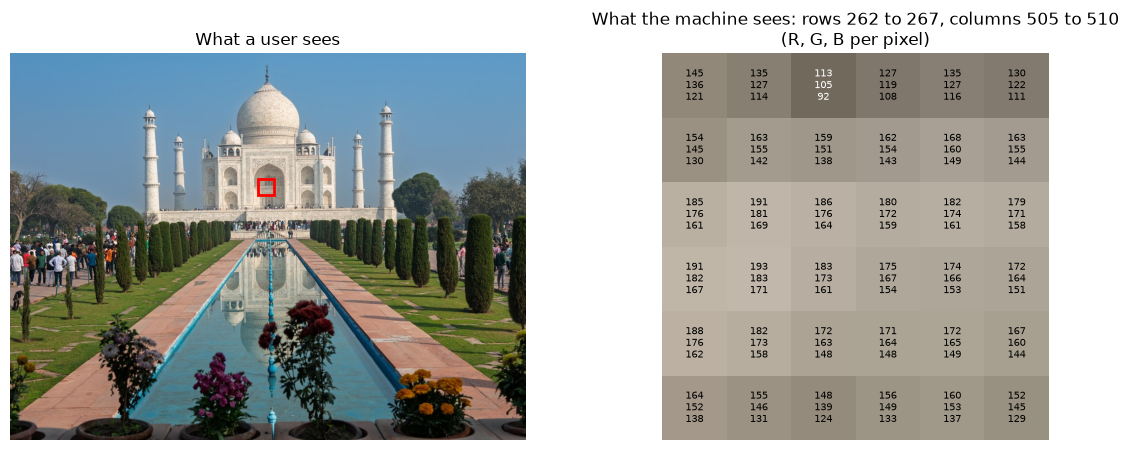

In [3]:
def show_patch(pixels, top, left, size=6):
    """Mark a patch on the photo and show its RGB values pixel by pixel."""
    patch = pixels[top:top + size, left:left + size]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [4, 3]})
    ax1.imshow(pixels)
    ax1.add_patch(Rectangle((left - 12, top - 12), size + 24, size + 24, fill=False, color="red", lw=2))
    ax1.set_title("What a user sees")
    ax1.axis("off")

    ax2.imshow(patch, interpolation="nearest")
    for i in range(size):
        for j in range(size):
            r, g, b = patch[i, j]
            ax2.text(j, i, f"{r}\n{g}\n{b}", ha="center", va="center", fontsize=7,
                     color="black" if patch[i, j].mean() > 110 else "white")
    ax2.set_title(f"What the machine sees: rows {top} to {top + size - 1}, columns {left} to {left + size - 1}\n(R, G, B per pixel)")
    ax2.axis("off")
    plt.tight_layout()
    plt.show()

show_patch(pixels, top=262, left=505)

None of these numbers is "dome", "sky", or "Taj Mahal". The book splits the gap into two parts.
Concepts such as "building", "sky", and "dome" are visible: a system that interprets the pixels
well enough can find them. Concepts such as "UNESCO World Heritage Site" or "where is Mumtaz
Mahal buried?" are not in the pixels at all. They need context from outside the image.

## 2. Metadata Inside the File

The JPEG file holds more than the pixels. We search the raw bytes of the file and the bytes of
the decoded pixel array for the name of the building.

In [4]:
raw = PHOTO.read_bytes()

display_md(
    f"| Bytes searched | Size | Occurrences of `Taj Mahal` |\n|---|---|---|\n"
    f"| the JPEG file | {len(raw):,} bytes | {raw.count(b'Taj Mahal')} |\n"
    f"| the decoded pixel array | {pixels.nbytes:,} bytes | {pixels.tobytes().count(b'Taj Mahal')} |"
)

| Bytes searched | Size | Occurrences of `Taj Mahal` |
|---|---|---|
| the JPEG file | 245,794 bytes | 1 |
| the decoded pixel array | 2,359,296 bytes | 0 |

The name is in the file but not in the pixels: someone wrote it into the metadata. The book lists
the standards that define where such metadata lives. We read two of them from this file.

### EXIF: written by the camera

EXIF stores what the camera knows at the moment of capture. The tags sit in a main directory and
in two sub-directories, one for exposure data and one for GPS.

In [5]:
def read_exif(img):
    """EXIF tags with readable names: main and Exif directories merged, GPS separate."""
    exif = img.getexif()
    tags = {TAGS.get(k, k): v for k, v in exif.items()}
    tags |= {TAGS.get(k, k): v for k, v in exif.get_ifd(IFD.Exif).items()}
    gps = {GPSTAGS.get(k, k): v for k, v in exif.get_ifd(IFD.GPSInfo).items()}
    return tags, gps

def gps_to_decimal(dms, ref):
    """(degrees, minutes, seconds) plus N/S/E/W -> signed decimal degrees."""
    d, m, s = (float(x) for x in dms)
    return (-1 if ref in ("S", "W") else 1) * (d + m / 60 + s / 3600)

exif, gps = read_exif(img)
lat = gps_to_decimal(gps["GPSLatitude"], gps["GPSLatitudeRef"])
lon = gps_to_decimal(gps["GPSLongitude"], gps["GPSLongitudeRef"])

print_table([
    ["DateTimeOriginal", exif["DateTimeOriginal"]],
    ["Make, Model", f"{exif['Make']}, {exif['Model']}"],
    ["LensModel, FocalLength", f"{exif['LensModel']}, {float(exif['FocalLength']):.0f} mm"],
    ["ExposureTime, FNumber, ISO", f"1/{1 / float(exif['ExposureTime']):.0f} s, f/{float(exif['FNumber']):.0f}, ISO {exif['ISOSpeedRatings']}"],
    ["GPSLatitude, GPSLongitude", f"{abs(lat):.5f} {gps['GPSLatitudeRef']}, {abs(lon):.5f} {gps['GPSLongitudeRef']}"],
], headers=["EXIF field", "Value"])
display_md(f"The file holds {len(exif)} EXIF tags and {len(gps)} GPS tags; the table shows a selection.")

| EXIF field                 | Value                         |
|:---------------------------|:------------------------------|
| DateTimeOriginal           | 2025:02:17 09:31:55           |
| Make, Model                | NIKON CORPORATION, NIKON D750 |
| LensModel, FocalLength     | 24.0-120.0 mm f/4.0, 46 mm    |
| ExposureTime, FNumber, ISO | 1/400 s, f/8, ISO 140         |
| GPSLatitude, GPSLongitude  | 27.17193 N, 78.04214 E        |

The file holds 53 EXIF tags and 5 GPS tags; the table shows a selection.

The values are generic but precise. A timestamp and a GPS position answer a query such as
"photos taken in Agra in 2025" without any content analysis. How close to the building was the
photographer? We compare the GPS position with the coordinates of the mausoleum
(27°10′30″ N, 78°02′31″ E).

In [6]:
MAUSOLEUM = (27 + 10 / 60 + 30 / 3600, 78 + 2 / 60 + 31 / 3600)

def distance_m(p, q, radius=6_371_000):
    """Great-circle (haversine) distance in meters between two (lat, lon) points."""
    (lat1, lon1), (lat2, lon2) = (map(math.radians, x) for x in (p, q))
    a = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 2 * radius * math.asin(math.sqrt(a))

d = distance_m((lat, lon), MAUSOLEUM)
display_md(
    f"The camera was **{d:.0f} m** {'south' if lat < MAUSOLEUM[0] else 'north'} of the mausoleum, "
    f"which fits a view from the main gate across the garden."
)

The camera was **342 m** south of the mausoleum, which fits a view from the main gate across the garden.

### IPTC in XMP: written by the photographer

The editorial fields of the IPTC standard (headline, caption, keywords, creator, copyright) are
stored as XMP, an XML packet inside the file. Several IPTC fields reuse Dublin Core elements:
the title is `dc:title`, the keywords are `dc:subject`, the caption is `dc:description`.

In [7]:
NS = {"rdf": "http://www.w3.org/1999/02/22-rdf-syntax-ns#", "dc": "http://purl.org/dc/elements/1.1/"}

def read_xmp_dc(img):
    """Dublin Core fields of the XMP packet, each as a list of values."""
    root = ET.fromstring(img.info["xmp"])
    return {f: [li.text for li in root.iterfind(f".//dc:{f}//rdf:li", NS)]
            for f in ["title", "description", "subject", "creator", "rights"]}

xmp = read_xmp_dc(img)
print_table([[f"dc:{field}", ", ".join(values) if values else "(empty)"] for field, values in xmp.items()],
            headers=["XMP field", "Value"])

| XMP field      | Value                                                         |
|:---------------|:--------------------------------------------------------------|
| dc:title       | The Taj Mahal, Agra, India                                    |
| dc:description | (empty)                                                       |
| dc:subject     | 2025, Nikon, d750, domain, india, public, public domain, tour |
| dc:creator     | Joe deSousa                                                   |
| dc:rights      | Public Domain                                                 |

The title names the building. The keywords serve the photographer's own archive: the year, the
camera, the license, the trip. "domain" and "public" are the two halves of "public domain". No
keyword says "mausoleum", "dome", or "UNESCO". The book makes the point in general terms: the
standards fix the names of the fields, not their values.

### An upload removes the metadata

Many platforms re-encode an uploaded photo and drop its metadata, mainly to protect the privacy
of the uploader. A re-encode that keeps only the pixels shows the effect.

In [8]:
buffer = BytesIO()
img.save(buffer, "JPEG", quality=90)     # pixels only: no exif= or xmp= argument
uploaded_bytes = buffer.getvalue()
uploaded = Image.open(BytesIO(uploaded_bytes))

rows = []
for name, data, im in [("original file", raw, img), ("re-encoded upload", uploaded_bytes, uploaded)]:
    tags, gps_tags = read_exif(im)
    rows.append([name, f"{len(data):,}", len(tags), len(gps_tags), "yes" if "xmp" in im.info else "no",
                 data.count(b"Taj Mahal")])
print_table(rows, headers=["File", "Bytes", "EXIF tags", "GPS tags", "XMP", "`Taj Mahal`"])

| File              |   Bytes |   EXIF tags |   GPS tags | XMP   |   `Taj Mahal` |
|:------------------|--------:|------------:|-----------:|:------|--------------:|
| original file     | 245,794 |          53 |          5 | yes   |             1 |
| re-encoded upload | 222,180 |           0 |          0 | no    |             0 |

The pixels are the same photo, but the date, the camera, the GPS position, and the only mention
of the Taj Mahal are gone.

## 3. Facets: Generic, Specific, and Abstract

Figure 9.5 of the book annotates the Taj Mahal photo along five facets. Each value is
**generic** (a general class), **specific** (an individual entity or fact), or **abstract** (a
subjective concept). We store that annotation as data. Two facets need a change for our photo.
The book's annotation dates its photo to 2006 and links it to an expert meeting of that year;
our photo was taken in 2025, and no specific event is known. The event facet therefore keeps
only its generic value, and the specific time comes from the EXIF field read above.

In [9]:
taken = exif["DateTimeOriginal"]          # "YYYY:MM:DD hh:mm:ss"

FACETS = {
    "object":  [("generic", "building, water, sky"),
                ("generic", "mausoleum, tomb, dome, minaret"),
                ("specific", "UNESCO World Heritage Site (since 1983)"),
                ("specific", "Taj Mahal")],
    "space":   [("generic", "outside"),
                ("specific", "India, Uttar Pradesh, Agra")],
    "event":   [("generic", "tourism, attraction")],
    "time":    [("generic", "daytime"),
                ("specific", f"{taken[:10].replace(':', '-')} (from EXIF)")],
    "context": [("generic", "Indian architecture"),
                ("specific", "Shah Jahan, Mumtaz Mahal, Islam"),
                ("specific", "built by Shah Jahan in memory of his wife Mumtaz Mahal, completed 1648"),
                ("abstract", "love, death, devotion, remembrance")],
}

print_table([[facet, level, values] for facet, entries in FACETS.items() for level, values in entries],
            headers=["Facet", "Level", "Values"])

| Facet   | Level    | Values                                                                 |
|:--------|:---------|:-----------------------------------------------------------------------|
| object  | generic  | building, water, sky                                                   |
| object  | generic  | mausoleum, tomb, dome, minaret                                         |
| object  | specific | UNESCO World Heritage Site (since 1983)                                |
| object  | specific | Taj Mahal                                                              |
| space   | generic  | outside                                                                |
| space   | specific | India, Uttar Pradesh, Agra                                             |
| event   | generic  | tourism, attraction                                                    |
| time    | generic  | daytime                                                                |
| time    | specific | 2025-02-17 (from EXIF)                                                 |
| context | generic  | Indian architecture                                                    |
| context | specific | Shah Jahan, Mumtaz Mahal, Islam                                        |
| context | specific | built by Shah Jahan in memory of his wife Mumtaz Mahal, completed 1648 |
| context | abstract | love, death, devotion, remembrance                                     |

Some values can be read from the pixels: "outside", "sky", "daytime", and "building" are visible
to any careful observer, human or machine. Others, such as "UNESCO", "Mumtaz Mahal", or
"completed 1648", need an annotator who knows the context. Facets also become filters in the
index: "space: Agra" or "time: 2025" narrows a result list with one click.

## 4. Two Annotators, Two Levels

The book lets two crowd workers annotate the same photo. Both are right, but Worker A knows the
building and writes specific terms, while Worker B describes what any observer sees. We measure
how much they agree, first by shared terms (after stopword removal and stemming), then with the
sentence embeddings of Chapter 5.

In [10]:
WORKER_A = "Taj Mahal, India, iconic building, 17th century"
WORKER_B = "religious building, great weather, few people outside, nice"
QUERY = "great architecture in India"

encoder = SentenceTransformer("all-MiniLM-L6-v2")

def compare(a, b):
    """Shared terms and cosine similarity of two short texts."""
    shared = sorted(set(pipeline(a)) & set(pipeline(b)))
    va, vb = encoder.encode([a, b], normalize_embeddings=True)
    return ", ".join(shared) or "(none)", float(va @ vb)

pairs = [
    ("Worker A", WORKER_A, "Worker B", WORKER_B),
    ("", "Taj Mahal", "", "religious building"),
    ("", "Taj Mahal", "", "mountain"),
    ("query", QUERY, "Worker A", WORKER_A),
    ("query", QUERY, "Worker B", WORKER_B),
]
rows = []
for la, a, lb, b in pairs:
    shared, cos = compare(a, b)
    rows.append([f"{la}: \"{a}\"" if la else f"\"{a}\"", f"{lb}: \"{b}\"" if lb else f"\"{b}\"", shared, cos])
print_table(rows, headers=["Text 1", "Text 2", "Shared terms", "Cosine"], floatfmt=("", "", "", ".2f"))

| Text 1                                                      | Text 2                                                                  | Shared terms   |   Cosine |
|:------------------------------------------------------------|:------------------------------------------------------------------------|:---------------|---------:|
| Worker A: "Taj Mahal, India, iconic building, 17th century" | Worker B: "religious building, great weather, few people outside, nice" | build          |     0.40 |
| "Taj Mahal"                                                 | "religious building"                                                    | (none)         |     0.35 |
| "Taj Mahal"                                                 | "mountain"                                                              | (none)         |     0.25 |
| query: "great architecture in India"                        | Worker A: "Taj Mahal, India, iconic building, 17th century"             | india          |     0.56 |
| query: "great architecture in India"                        | Worker B: "religious building, great weather, few people outside, nice" | great          |     0.43 |

The two workers share one term, "build". The embedding relates "Taj Mahal" to "religious
building" more closely than to "mountain", but only to a degree: the cosine stays far below the
value of a paraphrase. For the query, the shared terms mislead. Worker B matches "great" through
"great weather", which has nothing to do with architecture. Worker B's "nice" is the kind of
abstract judgment that two people rarely agree on, yet it may be close to what the user means.

## 5. Harvesting Context from the Web

When an image sits on a web page, the page describes it at almost no cost. The page
`data/ch09/news_page.html` follows the layout of Figures 9.11 and 9.12: a news article about the
Taj Mahal with a lead image, a caption, the article text, and a sidebar with unrelated news.

### Attributes and markup

The `<img>` tag carries a `title` and an `alt` text. A caption element sits below the image, and
the page has a title and a headline. The page also embeds schema.org markup that tells search
engines what the image shows.

In [11]:
news = BeautifulSoup(Path("data/ch09/news_page.html").read_text(encoding="utf-8"), "html.parser")
image = news.find("img")
schema = json.loads(news.find("script", type="application/ld+json").string)

print_table([
    ["`<img title>`", image["title"]],
    ["`<img alt>`", image["alt"]],
    ["`<figcaption>`", image.find_parent("figure").figcaption.get_text(strip=True)],
    ["`<title>`", news.title.get_text().replace("|", "\\|")],    # escape the pipe for the table
    ["`<h1>`", news.h1.get_text()],
    [f"schema.org `{schema['@type']}`", f"name: {schema['name']}; location: {schema['contentLocation']['name']}; "
                                        f"uploaded: {schema['uploadDate']}"],
], headers=["Source", "Text"])

| Source                   | Text                                                                               |
|:-------------------------|:-----------------------------------------------------------------------------------|
| `<img title>`            | Taj Mahal                                                                          |
| `<img alt>`              | Uttar Pradesh leaves the Taj Mahal out of its tourism booklet                      |
| `<figcaption>`           | Taj Mahal                                                                          |
| `<title>`                | Uttar Pradesh leaves the Taj Mahal out of its tourism booklet \| The Daily Example |
| `<h1>`                   | Uttar Pradesh leaves the Taj Mahal out of its tourism booklet                      |
| schema.org `ImageObject` | name: Taj Mahal; location: Agra, Uttar Pradesh, India; uploaded: 2017-10-08        |

The `alt` text repeats the headline, and the caption repeats the name. The words that users type,
such as "mausoleum" or "UNESCO", are in the article text. The harvester must decide which part of
the page belongs to the image.

### Source order versus visual zones

On early web pages, the describing text sat next to the `<img>` tag in the source. A window of a
few dozen tokens around the tag captured most of it. On this page, the sidebar comes first in
the source, and the style sheet moves it to the right column. We take 30 tokens before and after
the tag and mark every token that does not come from the image's `<article>` element, the column
that a browser renders around the image.

In [12]:
def source_window(soup, n=30):
    """n tokens before and after the first <img> in source order, each flagged in or out of the image's <article>."""
    image = soup.find("img")
    zone = image.find_parent("article")
    before, after, seen = [], [], False
    for node in soup.body.descendants:
        if node is image:
            seen = True
        elif isinstance(node, NavigableString) and not isinstance(node, Comment) \
                and node.parent.name not in ("script", "style"):
            inside = zone in node.parents
            (after if seen else before).extend((tok, inside) for tok in re.findall(r"\w+", node.lower()))
    return before[-n:], after[:n]

def show_window(before, after):
    """Window tokens as text; tokens from outside the image's zone in bold."""
    fmt = lambda toks: " ".join(t if inside else f"**{t}**" for t, inside in toks)
    leaked = sum(not inside for _, inside in before + after)
    display_md(
        f"**Before the image:** {fmt(before)}\n\n**[img]**\n\n**After the image:** {fmt(after)}\n\n"
        f"{leaked} of {len(before) + len(after)} window tokens come from outside the article (shown in bold)."
    )

show_window(*source_window(news))

**Before the image:** **the** **year** **opinion** **the** **new** **dilemma** **for** **search** **engines** **and** **social** **networks** uttar pradesh leaves the taj mahal out of its tourism booklet by a staff reporter 8 october 2017

**[img]**

**After the image:** taj mahal new delhi the government of the indian state of uttar pradesh has drawn criticism for leaving the taj mahal out of a new tourism booklet released on 2

12 of 60 window tokens come from outside the article (shown in bold).

The window before the image reaches into the sidebar and picks up words such as "search
engines" and "social networks". On screen, these words sit in a different column. Extractors
therefore judge proximity on the rendered page. Here, the `<article>` element stands in for the
visual zone, so the harvester takes the attributes, the page title, and the text of that zone.

In [13]:
def harvest(soup):
    """Text a harvester attaches to the first image: title, alt, page title, and the image's zone."""
    image = soup.find("img")
    zone = image.find_parent("article")
    return " ".join([image.get("title", ""), image.get("alt", ""), soup.title.get_text(), zone.get_text(" ")])

news_text = harvest(news)
terms = pipeline(news_text)
top = sorted(set(terms), key=lambda t: (-terms.count(t), t))[:12]
display_md(
    f"The harvested text has **{len(terms)} terms** after stopword removal and stemming. "
    f"The most frequent: {', '.join(f'{t} ({terms.count(t)})' for t in top)}."
)

The harvested text has **111 terms** after stopword removal and stemming. The most frequent: mahal (9), taj (9), booklet (5), leav (4), pradesh (4), tourism (4), uttar (4), agra (3), marbl (2), new (2), octob (2), site (2).

## 6. Can We Trust Metadata?

Harvested metadata is cheap, but someone with an interest wrote it. The first of Doctorow's
seven obstacles is "people lie". The page `data/ch09/hotel_ad_page.html` advertises a hotel.
Its only image shows the rooftop pool, but the `alt` text is stuffed with the words that people
use to search for the Taj Mahal. The same harvester reads both pages.

In [14]:
ad = BeautifulSoup(Path("data/ch09/hotel_ad_page.html").read_text(encoding="utf-8"), "html.parser")
ad_text = harvest(ad)

print_table([
    [name, soup.find("img")["src"], soup.find("figcaption").get_text(strip=True), len(pipeline(text))]
    for name, soup, text in [("news page", news, news_text), ("hotel ad", ad, ad_text)]
], headers=["Page", "Image file", "Caption", "Harvested terms"])

| Page      | Image file                 | Caption          |   Harvested terms |
|:----------|:---------------------------|:-----------------|------------------:|
| news page | /img/2017/10/taj-mahal.jpg | Taj Mahal        |               111 |
| hotel ad  | /img/pool-deluxe.jpg       | Our rooftop pool |                49 |

The caption of the ad says "Our rooftop pool". The harvester does not look at the image, so
nothing in its output reveals that the picture shows a pool. The next section scores both pages
against the queries.

## Payoff: Five Queries, Four Sources

We return to the queries of Figure 9.4 and match each one against four metadata sources: the
photographer's XMP fields, the faceted annotation, the harvested news page, and the hotel ad.
A source matches a query term if the stemmed term occurs in its text. The cell shows how many
query terms each source matches.

In [15]:
SOURCES = {
    "photographer (XMP)": " ".join(xmp["title"] + xmp["description"] + xmp["subject"]),
    "facets (annotator)": " ".join(values for entries in FACETS.values() for _, values in entries),
    "news page (harvested)": news_text,
    "hotel ad (harvested)": ad_text,
}

def matched(query, text):
    """Query terms (stemmed, stopwords removed) that occur in the text."""
    vocab = set(pipeline(text))
    return [t for t in pipeline(query) if t in vocab]

rows = []
for q in QUERIES:
    n = len(pipeline(q))
    rows.append([q] + [f"{len(matched(q, text))}/{n}" for text in SOURCES.values()])
print_table(rows, headers=["Query"] + list(SOURCES))

| Query                          | photographer (XMP)   | facets (annotator)   | news page (harvested)   | hotel ad (harvested)   |
|:-------------------------------|:---------------------|:---------------------|:------------------------|:-----------------------|
| building, outdoor, sky         | 0/3                  | 2/3                  | 0/3                     | 3/3                    |
| mausoleum, tomb, dome, minaret | 0/4                  | 4/4                  | 3/4                     | 4/4                    |
| UNESCO World Heritage Site     | 0/4                  | 4/4                  | 4/4                     | 4/4                    |
| Taj Mahal, Indian architecture | 2/4                  | 4/4                  | 3/4                     | 4/4                    |
| where is Mumtaz Mahal buried?  | 1/3                  | 2/3                  | 2/3                     | 3/3                    |

Each source covers a different part of the gap:

- **The photographer's metadata** matches the name, and "mahal" of "Mumtaz Mahal" only through
  "Taj Mahal", by accident. The camera fields are precise, but they answer "where" and "when",
  not "what".
- **The faceted annotation** matches almost every term, including the context queries that no
  pixel analysis can answer. It misses "outdoor" (it says "outside") and "buried". An annotator who knows the building wrote it, which is exactly what does
  not scale to millions of photos.
- **The news page** matches the context queries ("UNESCO", "Mumtaz Mahal") through the article
  text, but not the visual terms "building, outdoor, sky": a journalist does not describe what
  every reader sees.
- **The hotel ad** matches every term of every query, and its image shows a swimming pool.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Metadata is a claim, not a fact</strong><br>
The keyword path bridges the semantic gap with whatever someone wrote about the item. Curated annotation is good but expensive, embedded metadata describes the camera more than the content, and harvested text can be wrong or manipulated. Nothing in a text match tells these cases apart. The next demo describes the content from the content itself.
</div>

## Summary

- An image stores millions of numbers and no concepts. The name of the building appears only in
  the metadata.
- EXIF records when, where, and how a photo was taken; IPTC fields in XMP carry what the
  photographer chose to write. An upload often removes both.
- Facets organize generic, specific, and abstract values. Some values are visible in the pixels;
  others need context.
- Two annotators describe the same photo at different levels. Shared terms miss the relation or
  match by accident; embeddings relate the terms, but only to a degree.
- Harvesting text from a web page works if the harvester finds the right zone. The source order
  of modern pages is not the visual order.
- A keyword match does not reveal whether the metadata is true.

## Try it yourself

1. Run `read_exif` and `read_xmp_dc` on a photo from your phone. Which fields does it carry? Send
   the photo to yourself with a messenger app and compare the received copy.
2. Call `show_window(*source_window(news, n=10))` and then with `n=60`. From which window size on
   does the sidebar leak into the window?
3. Add your own query to `QUERIES`, for example "white marble monument", and rerun the payoff
   cell. Then compare the query with each source text using `compare(query, text)` from
   section 4. Does the embedding find a source that shares no terms with the query?